# EARTHSC 5201: Homework 4

## Rory Levinson

### Question 1

#### Using the P-wave travel times listed in Table 6.1 in the book, apply the geometrical spreading equation (6.23) to predict the relative amplitude of P-waves recorded at the surface from an isotropic surface source at ranges of 30°, 60° and 90° (Figure 6.18 in the book). Assume the P velocity is 5.8 km/s. If the amplitude at 30° is one, what is the amplitude at 60° and 90°? Hints: Be sure to convert the psph values in Table 6.1 to s/radian in order to obtain correct units. Check the values you compute for the ray takeoff angle theta to be sure they look reasonable.

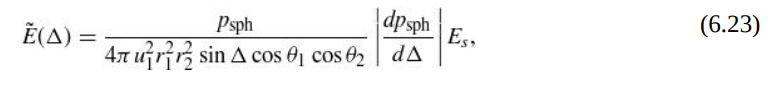

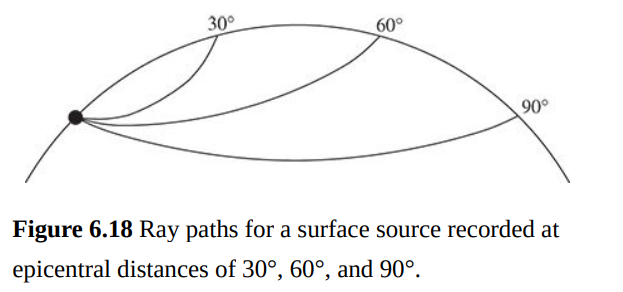

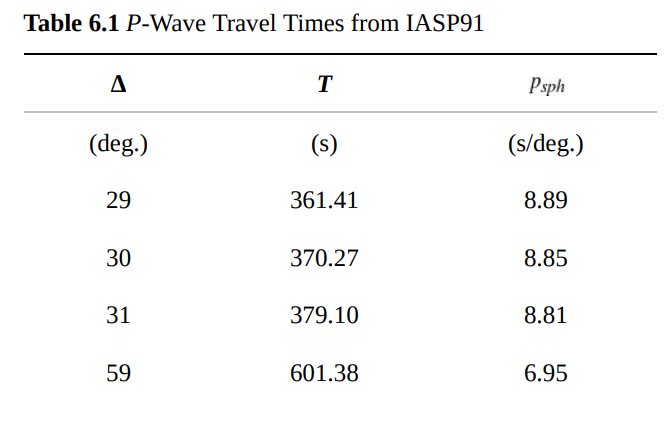
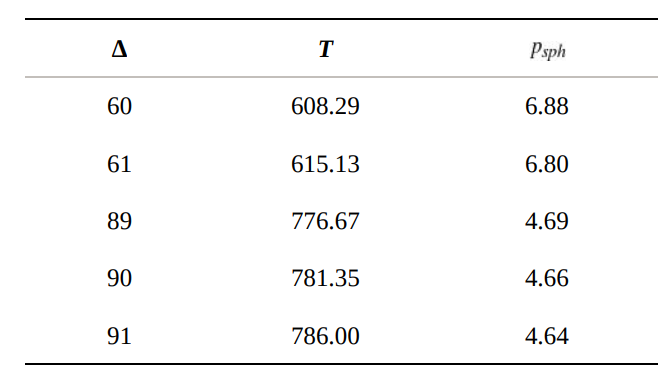

In [15]:
import numpy as np

v = 5.8
R = 6371
degrees = np.pi / 180

# travel-time table values (s/degree)
data = {
    30: [8.89, 8.85, 8.81],
    60: [6.95, 6.88, 6.80],
    90: [4.69, 4.66, 4.64]
}

energy_values = {}

for delta, values in data.items():
    p_minus, p, p_plus = values
    p_rad = p / degrees
    dp = (p_plus - p_minus) / 2
    dp_dDelta = dp / degrees**2
    theta = np.arcsin(p_rad * v / R)

    E = (p_rad * abs(dp_dDelta)) / (
        np.sin(delta * degrees) * np.cos(theta)**2
    )

    energy_values[delta] = E

E30 = energy_values[30]

for delta in [30, 60, 90]:
    relative_amplitude = np.sqrt(energy_values[delta] / E30)
    print(f"Amplitude at {delta} degrees: {relative_amplitude:.4f}")

Amplitude at 30 degrees: 1.0000
Amplitude at 60 degrees: 0.8718
Amplitude at 90 degrees: 0.3710


In [2]:
p_values = [8.85, 6.88, 4.66]

for distance, p in zip([30, 60, 90], p_values):
    p_rad = p * (180 / np.pi)
    theta = np.degrees(np.arcsin(p_rad * v / R))

    print(f"{distance} degrees: {theta:.2f} degrees")

30 degrees: 27.49 degrees
60 degrees: 21.03 degrees
90 degrees: 14.07 degrees


#### The relative amplitude at 30 degrees is 1.0000, the relative amplitude at 60 degrees is 0.8718, and the relative amplitude at 90 degrees is 0.3710.

### Question 2a

#### Estimate the attenuation for waves of 30 s period (0.033 Hz) for PcP ray paths at vertical incidence. Consider only the intrinsic attenuation along the ray paths; do not include the reflection coefficient at the core-mantle boundary or geometrical spreading. Be sure to count both the surface-to-CMB and CMB-to-surface legs. You can get the PREM P velocities from Figure 1.1 or the values in Appendix A. You may estimate the travel times through the different Q layers in PREM by assuming a fixed velocity within each layer (e.g., use the average velocity between 2 and 80 km, the average between 80-220 km, etc.). Note that in this case the surface is assumed to be the bottom of the ocean at 3 km depth. Compute t* for PcP. Finally, give the attenuated amplitude of the PcP ray assuming it had an initial amplitude of one.

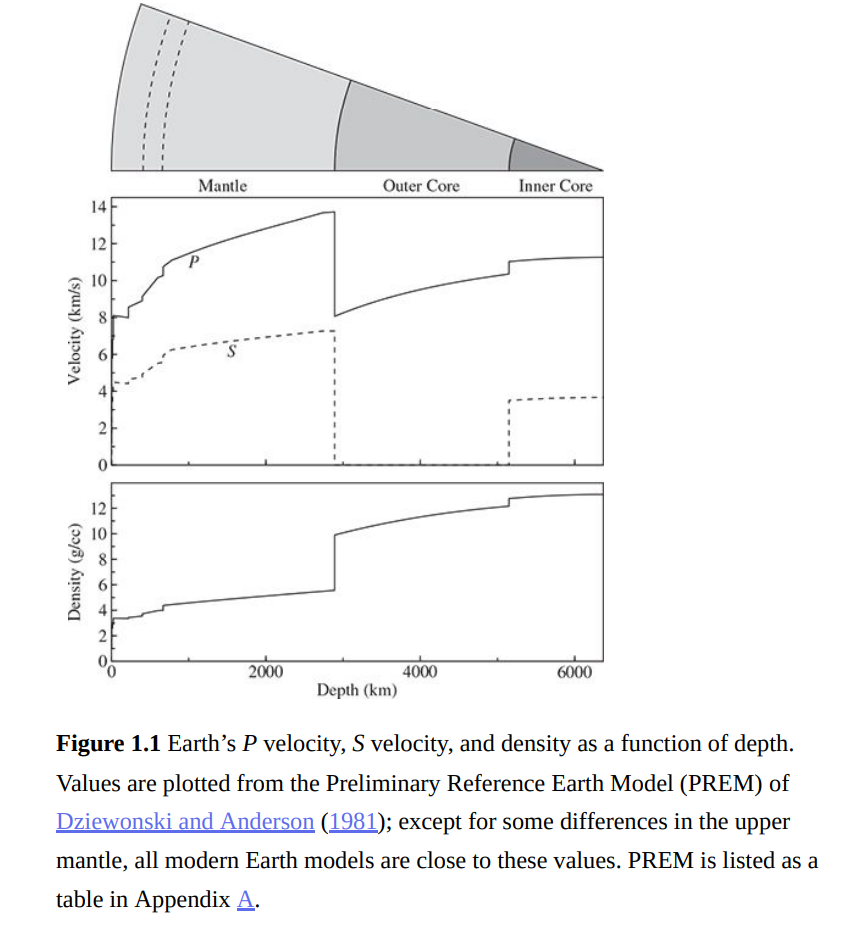

In [3]:
import numpy as np
import pandas as pd

f = 0.033
A0 = 1.0
R = 6371

top = np.array([3, 24, 80, 220, 670])
bottom = np.array([24, 80, 220, 670, 2891])

Vp = np.array([6.8, 8.0, 8.1, 9.0, 11.5])

Vs = np.array([3.9, 4.5, 4.5, 4.9, 6.4])

Qmu = np.array([600, 600, 80, 143, 312])
Qk = np.array([57823, 57823, 57823, 57823, 57823])

Qp = 1 / (
    (1 - (4/3) * (Vs/Vp)**2) / Qk
    + ((4/3) * (Vs/Vp)**2) / Qmu
)

thickness = bottom - top
travel_time = thickness / Vp

tstar_layer = travel_time / Qp
tstar_oneway = np.sum(tstar_layer)
tstar_total = 2 * tstar_oneway

attenuation_factor = np.exp(-np.pi * f * tstar_total)
A = A0 * attenuation_factor
attenuation_loss = (1 - attenuation_factor) * 100

results = pd.DataFrame({
    "Layer (km)": [
        "3-24", "24-80", "80-220",
        "220-670", "670-2891"
    ],
    "Vp (km/s)": Vp,
    "Vs (km/s)": Vs,
    "Qp": Qp,
    "Travel time (s)": travel_time,
    "t* contribution (s)": tstar_layer
})

print("Layer-by-Layer Results:")
print(results.to_string(index=False))

print("\nFinal PcP Attenuation Results:")
print("One-way travel time:", round(np.sum(travel_time), 3), "seconds")
print("One-way t*:", round(tstar_oneway, 5), "seconds")
print("Total PcP t*:", round(tstar_total, 5), "seconds")
print("Intrinsic attenuation factor:", round(attenuation_factor, 5))
print("Initial amplitude:", A0)
print("Attenuated amplitude:", round(A, 5))

### Question 2b

####  Using the approximation t(beta)* = 4t(alpha)*, compute the attenuated amplitude of ScS at 30 s period.

In [4]:
import numpy as np

f = 0.033
A0 = 1.0

tstar_alpha = 0.98532

tstar_beta = 4 * tstar_alpha

attenuation_factor = np.exp(-np.pi * f * tstar_beta)

A_ScS = A0 * attenuation_factor

attenuation_loss = (1 - attenuation_factor) * 100

print("ScS t*:", round(tstar_beta, 5), "seconds")
print("ScS attenuation factor:", round(attenuation_factor, 5))
print("ScS attenuated amplitude:", round(A_ScS, 5))
print("Percentage amplitude lost:", round(attenuation_loss, 2), "%")

ScS t*: 3.94128 seconds
ScS attenuation factor: 0.66458
ScS attenuated amplitude: 0.66458
Percentage amplitude lost: 33.54 %


### Question 2c

#### Repeat (a) and (b) for 1 second period PcP and ScS waves.

In [5]:
import numpy as np

T = 1.0
f = 1 / T
A0 = 1.0

tstar_alpha = 0.98532

A_PcP = A0 * np.exp(-np.pi * f * tstar_alpha)

tstar_beta = 4 * tstar_alpha

A_ScS = A0 * np.exp(-np.pi * f * tstar_beta)

loss_PcP = (1 - A_PcP) * 100
loss_ScS = (1 - A_ScS) * 100

print("Frequency:", f, "Hz")

print("\nPcP at 1-second period:")
print("t*:", round(tstar_alpha, 5), "seconds")
print("Attenuated amplitude:", A_PcP)
print("Percentage amplitude lost:", round(loss_PcP, 2), "%")

print("\nScS at 1-second period:")
print("t*:", round(tstar_beta, 5), "seconds")
print("Attenuated amplitude:", A_ScS)
print("Percentage amplitude lost:", round(loss_ScS, 4), "%")

Frequency: 1.0 Hz

PcP at 1-second period:
t*: 0.98532 seconds
Attenuated amplitude: 0.045253553866450434
Percentage amplitude lost: 95.47 %

ScS at 1-second period:
t*: 3.94128 seconds
Attenuated amplitude: 4.1938294408032325e-06
Percentage amplitude lost: 99.9996 %


### Question 3a

#### Recall equation 7.19 for the vibroseis sweep function:

#### Solve for f0 and b in the case of a 20-s long sweep between 1 and 4 Hz. Hint: b=3/20 is incorrect. The derivative of phase is equal to the change in frequency.

In [6]:
f_start = 1
f_end = 4
duration = 20

f0 = f_start

b = (f_end - f_start) / (2 * duration)

print("f0 =", f0, "Hz")
print("b =", b, "Hz/s")

f_final = f0 + 2 * b * duration

print("Ending frequency =", f_final, "Hz")

f0 = 1 Hz
b = 0.075 Hz/s
Ending frequency = 4.0 Hz


### Question 3b

#### Compute and plot v(t) for this sweep function between 0 and 20 seconds. Assume that A(t)=sin^2 * (pi*t/20) (this is a Hanning taper that goes to zero at t=0 and t=20).

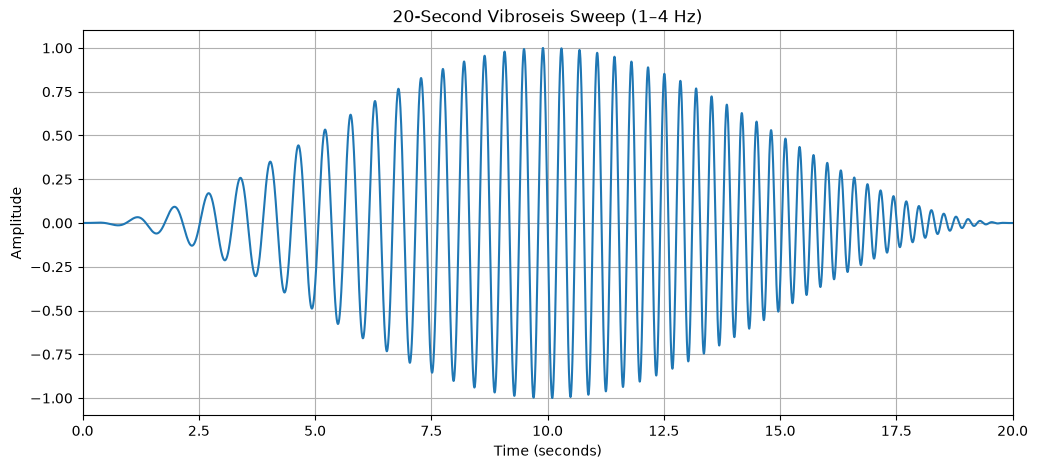

In [7]:
import numpy as np
import matplotlib.pyplot as plt

f0 = 1.0
b = 0.075
duration = 20

t = np.linspace(0, 20, 10000)

A = np.sin(np.pi * t / 20)**2

v = A * np.sin(2 * np.pi * (f0 + b*t) * t)

plt.figure(figsize=(12, 5))
plt.plot(t, v)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("20-Second Vibroseis Sweep (1–4 Hz)")
plt.grid(True)

plt.xlim(0, 20)
plt.show()

### Question 3c

#### Compute and plot the autocorrelation of v(t) between –2 and 2 seconds.

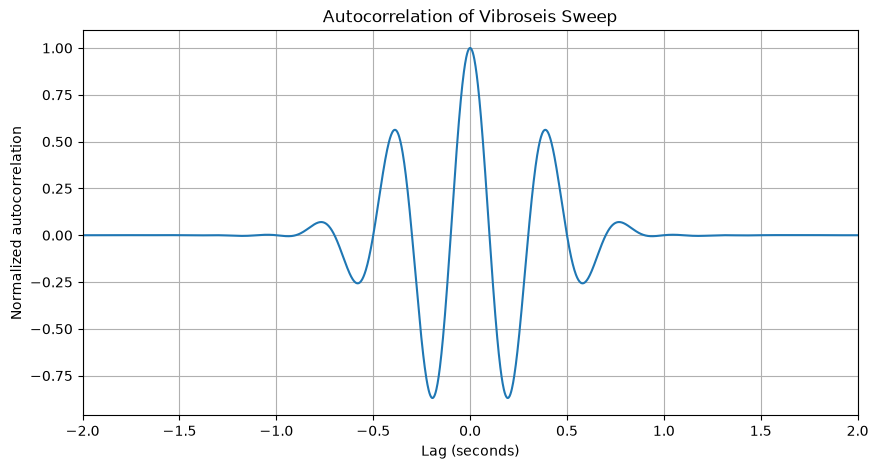

In [8]:
import numpy as np
import matplotlib.pyplot as plt

f0 = 1.0
b = 0.075
duration = 20.0
fs = 500
dt = 1 / fs

t = np.arange(0, duration, dt)

A = np.sin(np.pi * t / duration)**2

v = A * np.sin(2 * np.pi * (f0 + b*t) * t)

def xcorr(a, b):
    return np.convolve(a, b[::-1], mode="full")

R = xcorr(v, v)

R = R * dt

lags = (np.arange(len(R)) - (len(v) - 1)) * dt

R = R / np.max(R)

mask = (lags >= -2) & (lags <= 2)

plt.figure(figsize=(10, 5))
plt.plot(lags[mask], R[mask])

plt.xlabel("Lag (seconds)")
plt.ylabel("Normalized autocorrelation")
plt.title("Autocorrelation of Vibroseis Sweep")
plt.xlim(-2, 2)
plt.grid(True)
plt.show()

### Question 3d

#### Repeat (b) and (c), but this time assume that A(t) is only a short 2-s long taper at each end of the sweep, so you will have:
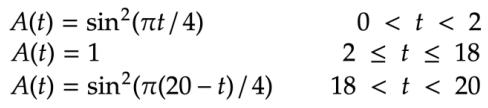

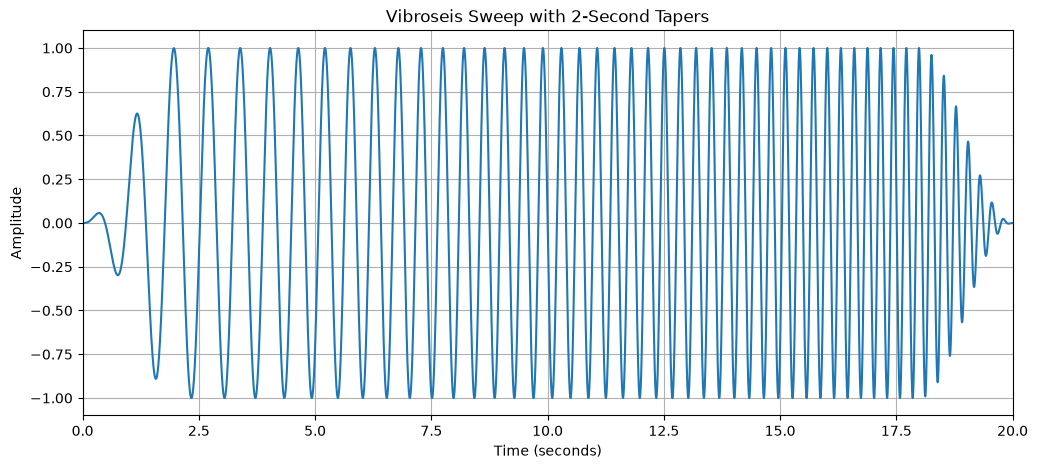

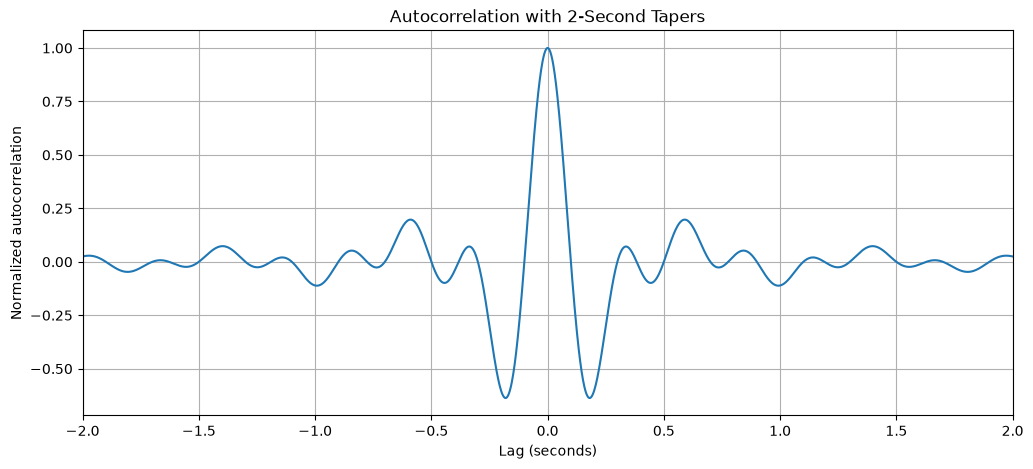

Autocorrelation at zero lag: 1.0


In [9]:
import numpy as np
import matplotlib.pyplot as plt

f0 = 1.0
b = 0.075
duration = 20.0
fs = 500
dt = 1 / fs
t = np.arange(0, duration, dt)

A = np.ones_like(t)

A[t < 2] = np.sin(np.pi * t[t < 2] / 4)**2

A[t > 18] = np.sin(np.pi * (20 - t[t > 18]) / 4)**2

v = A * np.sin(2 * np.pi * (f0 + b*t) * t)

plt.figure(figsize=(12, 5))
plt.plot(t, v)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Vibroseis Sweep with 2-Second Tapers")
plt.xlim(0, 20)
plt.grid()
plt.show()

def xcorr(a, b):
    return np.convolve(a, b[::-1], mode="full")

R = xcorr(v, v) * dt

lags = (np.arange(len(R)) - (len(v)-1)) * dt

R = R / R[len(v)-1]

mask = (lags >= -2) & (lags <= 2)

plt.figure(figsize=(12, 5))
plt.plot(lags[mask], R[mask])

plt.xlabel("Lag (seconds)")
plt.ylabel("Normalized autocorrelation")
plt.title("Autocorrelation with 2-Second Tapers")
plt.xlim(-2, 2)
plt.grid()
plt.show()

print("Autocorrelation at zero lag:", R[len(v)-1])

### Question 3e

#### What happens to the pulse if autocorrelation is applied a second time to the autocorrelation of v(t)? For this, you will have the case below:
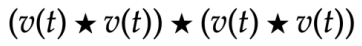

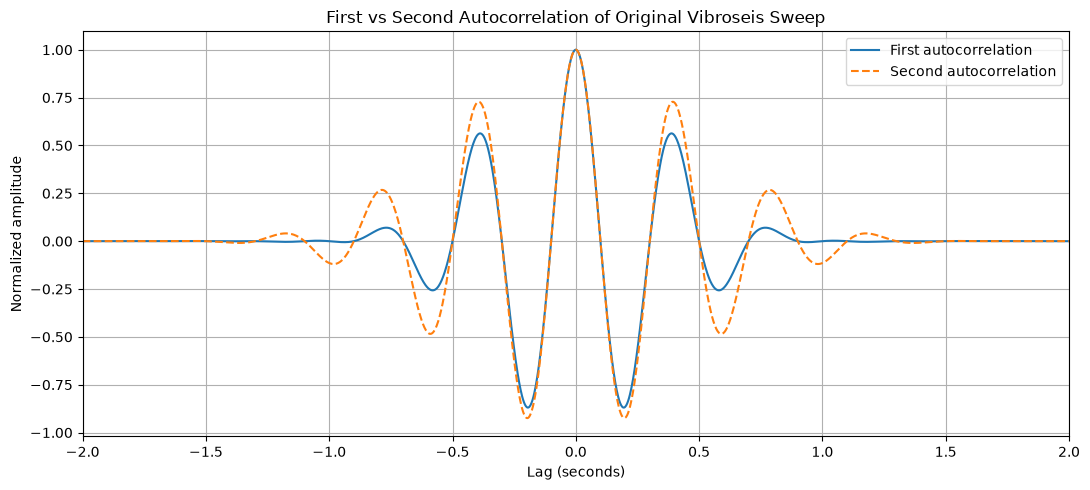

In [10]:
import numpy as np
import matplotlib.pyplot as plt

f0 = 1.0
b = 0.075
duration = 20.0
fs = 500
dt = 1 / fs
t = np.arange(0, duration, dt)

A = np.sin(np.pi * t / 20)**2

v = A * np.sin(2 * np.pi * (f0 + b*t) * t)

def xcorr(a, b):
    return np.convolve(a, b[::-1], mode="full")

R1 = xcorr(v, v)

R1 = R1 / R1[len(v)-1]

lag1 = (np.arange(len(R1)) - (len(v)-1)) * dt

R2 = xcorr(R1, R1)

R2 = R2 / R2[len(R1)-1]

lag2 = (np.arange(len(R2)) - (len(R1)-1)) * dt

mask1 = (lag1 >= -2) & (lag1 <= 2)
mask2 = (lag2 >= -2) & (lag2 <= 2)

plt.figure(figsize=(11, 5))

plt.plot(lag1[mask1], R1[mask1],
         label="First autocorrelation")

plt.plot(lag2[mask2], R2[mask2],
         linestyle="--",
         label="Second autocorrelation")

plt.xlabel("Lag (seconds)")
plt.ylabel("Normalized amplitude")
plt.title("First vs Second Autocorrelation of Original Vibroseis Sweep")
plt.xlim(-2, 2)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

#### Applying autocorrelation a second time to the autocorrelation of v(t) produces a with a similar central peak but a different side lobe structure. Both autocorrelations are symmetric around zero lag and have a maximum normalized amplitude of one at zero lag. The second autocorrelation has larger side peaks, particularly around ~0.4 seconds. This occurs because autocorrelating the signal again changes its frequency and amplitude distribution, resulting in a broader correlation structure and modified side lobes.

# All done!